# D-1: ARR over time
**ARR** = revenue from repeat customers (a visit after their `signup_date`) over the trailing 12 months.
Charts go to `results/d_customers_arr/`. Slide 3.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
import pandas as pd

from src import config as C
from src.metrics import load

OUT = ROOT / "results" / "d_customers_arr"
OUT.mkdir(parents=True, exist_ok=True)

# Chart style (validated default palette: slot 1 blue, slot 2 orange; recessive grid and axes)
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#5f5e5a", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "font.size": 11,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "lines.linewidth": 2,
})
EVENT_LABELS = {
    "competitor_open": "Competitor opens", "loyalty_launch": "Loyalty launch",
    "pilates_start": "Pilates push", "repairs_launch": "Free repairs",
    "website_launch": "Website", "new_manager": "New manager",
}


def mark_events(ax, ymax):
    for i, (key, label) in enumerate(EVENT_LABELS.items()):
        d = C.EVENTS[key]
        ax.axvline(d, color=INK2, lw=0.8, ls=(0, (3, 3)), zorder=1)
        ax.text(d, ymax * (0.995 - 0.035 * (i % 2)), " " + label, color=INK2, fontsize=9, va="top")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 5, 9]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

## 1. Company ARR by month
Plotted from Nov 2023. Before that there are fewer than 12 months of history, so ARR is understated.

In [2]:
cm = load("customer_month")
arr = cm.groupby("month")["arr_12m"].sum()
arr = arr[arr.index >= "2023-11-01"]

trough_m = arr.idxmin()
summary = pd.Series({
    "ARR Nov 2023 ($M)": arr.iloc[0] / 1e6,
    "ARR at competitor open, Mar 2024 ($M)": arr[C.COMPETITOR_OPEN.to_period("M").to_timestamp()] / 1e6,
    f"ARR trough, {trough_m:%b %Y} ($M)": arr.min() / 1e6,
    "ARR Oct 2026 ($M)": arr.iloc[-1] / 1e6,
    "Change trough to Oct 2026 (%)": (arr.iloc[-1] / arr.min() - 1) * 100,
    "Change Mar 2024 to Oct 2026 (%)": (arr.iloc[-1] / arr[C.COMPETITOR_OPEN.to_period("M").to_timestamp()] - 1) * 100,
}).round(2)
summary

ARR Nov 2023 ($M)                         6.15
ARR at competitor open, Mar 2024 ($M)     6.23
ARR trough, Feb 2025 ($M)                 5.53
ARR Oct 2026 ($M)                         6.67
Change trough to Oct 2026 (%)            20.75
Change Mar 2024 to Oct 2026 (%)           7.06
dtype: float64

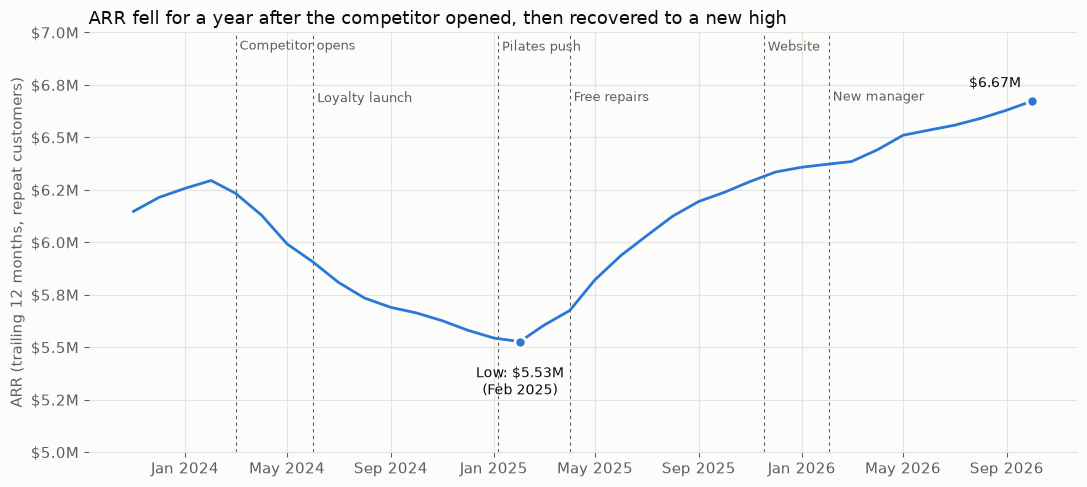

In [3]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(arr.index, arr / 1e6, color=BLUE)
ax.plot([trough_m, arr.index[-1]], [arr.min() / 1e6, arr.iloc[-1] / 1e6], "o", color=BLUE, ms=8,
         mec="#fcfcfb", mew=2, zorder=3)
ax.annotate(f"Low: ${arr.min()/1e6:.2f}M\n({trough_m:%b %Y})", (trough_m, arr.min() / 1e6),
            xytext=(0, -38), textcoords="offset points", ha="center", color=INK, fontsize=10)
ax.annotate(f"${arr.iloc[-1]/1e6:.2f}M", (arr.index[-1], arr.iloc[-1] / 1e6),
            xytext=(-8, 10), textcoords="offset points", ha="right", color=INK, fontsize=10)
ymin, ymax = 5.0, 7.0
ax.set_ylim(ymin, ymax)
mark_events(ax, ymax)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x:.1f}M"))
ax.set_title("ARR fell for a year after the competitor opened, then recovered to a new high",
             loc="left", color=INK, fontsize=13)
ax.set_ylabel("ARR (trailing 12 months, repeat customers)")
fig.tight_layout()
fig.savefig(OUT / "d1_arr_line.png", dpi=200)
plt.show()

## 2. What drove the recovery: more customers, or more spend per customer?
ARR is a 12-month rolling total, so it lags. To see *when* things changed, compare each month's repeat
revenue and active repeat customers with the **same calendar month in Mar 2023 – Feb 2024** (the year before
the competitor). This removes seasonality. Shown as a 3-month rolling average; 100 = pre-competitor level.

In [4]:
v = load("visits")
rv = v[v["is_repeat_visit"]]
g = rv.groupby("month").agg(revenue=("revenue", "sum"), customers=("customer_id", "nunique"))
g["rev_per_customer"] = g["revenue"] / g["customers"]

base = g.loc["2023-03-01":"2024-02-01"].copy()
base.index = base.index.month
post = g.loc["2024-03-01":].copy()
idx = post.div(base.loc[post.index.month].values) * 100
idx_smooth = idx.rolling(3, min_periods=1).mean()

periods = {"Year 1 (Mar 2024 – Feb 2025)": ("2024-03-01", "2025-02-01"),
           "Year 2 (Mar 2025 – Feb 2026)": ("2025-03-01", "2026-02-01"),
           "Year 3 so far (Mar – Oct 2026)": ("2026-03-01", "2026-10-01")}
rows = {}
for name, (a, b) in periods.items():
    p = g.loc[a:b]
    bm = base.loc[p.index.month]
    rows[name] = {
        "repeat revenue vs pre-competitor (%)": (p.revenue.sum() / bm.revenue.sum() - 1) * 100,
        "active repeat customers vs pre-competitor (%)": (p.customers.mean() / bm.customers.mean() - 1) * 100,
        "revenue per active customer vs pre-competitor (%)":
            ((p.revenue.sum() / p.customers.sum()) / (bm.revenue.sum() / bm.customers.sum()) - 1) * 100,
    }
recovery = pd.DataFrame(rows).T.round(1)
recovery

,repeat revenue vs pre-competitor (%),active repeat customers vs pre-competitor (%),revenue per active customer vs pre-competitor (%)
Year 1 (Mar 2024 – Feb 2025),-12.2,-18.7,8.0
Year 2 (Mar 2025 – Feb 2026),1.2,-8.8,11.0
Year 3 so far (Mar – Oct 2026),10.4,-5.3,16.6


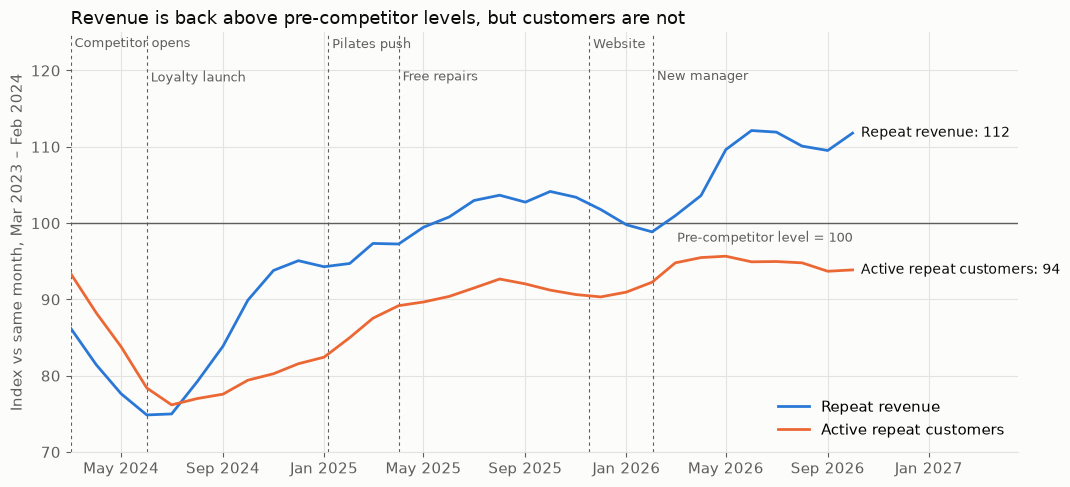

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.axhline(100, color=INK2, lw=1)
ax.plot(idx_smooth.index, idx_smooth["revenue"], color=BLUE, label="Repeat revenue")
ax.plot(idx_smooth.index, idx_smooth["customers"], color=ORANGE, label="Active repeat customers")
for col, colr, lab in [("revenue", BLUE, "Repeat revenue"), ("customers", ORANGE, "Active repeat customers")]:
    y = idx_smooth[col].iloc[-1]
    ax.annotate(f"{lab}: {y:.0f}", (idx_smooth.index[-1], y), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK, fontsize=10)
ax.text(pd.Timestamp("2026-10-01"), 99, "Pre-competitor level = 100", color=INK2, fontsize=9, va="top", ha="right")
ymin, ymax = 70, 125
ax.set_ylim(ymin, ymax)
mark_events(ax, ymax)
ax.legend(loc="lower right", frameon=False)
ax.set_xlim(idx_smooth.index[0], idx_smooth.index[-1] + pd.Timedelta(days=200))
ax.set_title("Revenue is back above pre-competitor levels, but customers are not",
             loc="left", color=INK, fontsize=13)
ax.set_ylabel("Index vs same month, Mar 2023 – Feb 2024")
fig.tight_layout()
fig.savefig(OUT / "d1_recovery_index.png", dpi=200)
plt.show()

## 3. Who holds the ARR now (by age band)
Shows where the recovered ARR sits. Read with A-1: 18–24s left after the competitor opened.

In [6]:
cu = load("customers")[["customer_id", "age_band"]]
by_age = (cm.merge(cu, on="customer_id").groupby(["month", "age_band"])["arr_12m"].sum().unstack() / 1e6)
age_tbl = by_age.loc[[pd.Timestamp("2024-02-01"), arr.idxmin(), pd.Timestamp("2026-10-01")]].T.round(2)
age_tbl.columns = ["Feb 2024 ($M)", f"{arr.idxmin():%b %Y} ($M)", "Oct 2026 ($M)"]
age_tbl["change Feb 2024 to Oct 2026 (%)"] = ((age_tbl.iloc[:, 2] / age_tbl.iloc[:, 0] - 1) * 100).round(1)
age_tbl

,Feb 2024 ($M),Feb 2025 ($M),Oct 2026 ($M),change Feb 2024 to Oct 2026 (%)
age_band,,,,
18-24,1.19,0.68,0.64,-46.2
25-34,2.15,1.87,2.34,8.8
35-44,1.55,1.59,2.00,29.0
45-54,0.90,0.91,1.08,20.0
55+,0.40,0.37,0.48,20.0
Unknown,0.11,0.10,0.13,18.2
